In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Random number generator for reproducible results
rng = np.random.default_rng(42)

# Generate 1,000 hypothetical candidates
n_candidates = 1000

candidates = pd.DataFrame({
    "candidate_id": range(n_candidates),
    "lipophilicity": rng.uniform(0, 10, n_candidates),
    "molecular_size": rng.uniform(300, 1000, n_candidates),
    "charge": rng.uniform(-2, 2, n_candidates),
    "flexibility": rng.uniform(0, 1, n_candidates)
})

print("Number of candidates:", len(candidates))
display(candidates.head())


Number of candidates: 1000


,candidate_id,lipophilicity,molecular_size,charge,flexibility
0,0,7.739560,343.444175,1.370928,0.829221
1,1,4.388784,620.783429,-0.214442,0.594096
2,2,8.585979,390.321040,1.811901,0.244855
3,3,6.973680,406.628697,0.603178,0.745675
4,4,0.941773,742.597969,-1.536405,0.084481


In [2]:
def true_performance(df):
    lipophilicity_effect = np.exp(
        -((df["lipophilicity"] - 6) ** 2) / 4
    )

    size_effect = np.exp(
        -((df["molecular_size"] - 600) ** 2) / 40000
    )

    charge_effect = np.exp(
        -((df["charge"] - 0.5) ** 2) / 1.5
    )

    flexibility_effect = 0.5 + 0.5 * df["flexibility"]

    return (
        lipophilicity_effect
        * size_effect
        * charge_effect
        * flexibility_effect
    )

# The simulator knows the true performance
candidates["true_performance"] = true_performance(candidates)

print("Best possible candidate in library:")
display(
    candidates.nlargest(5, "true_performance")
)

Best possible candidate in library:


,candidate_id,lipophilicity,molecular_size,charge,flexibility,true_performance
923,923,5.423644,551.766406,0.696577,0.922943,0.813621
905,905,6.525192,611.281620,0.595100,0.668494,0.771519
459,459,6.364083,564.816876,0.109599,0.791847,0.759121
821,821,5.945676,644.268807,0.716581,0.627752,0.750549
489,489,5.657719,632.892821,0.434639,0.498375,0.706133


In [3]:
# Randomly select 30 candidates
initial_ids = rng.choice(
    candidates["candidate_id"],
    size=30,
    replace=False
)

initial_screen = candidates[
    candidates["candidate_id"].isin(initial_ids)
].copy()

# Simulate experimental measurement noise
initial_screen["measured_performance"] = (
    initial_screen["true_performance"]
    + rng.normal(0, 0.03, len(initial_screen))
)

initial_screen["measured_performance"] = (
    initial_screen["measured_performance"].clip(0, 1)
)

print("Initial experiments:", len(initial_screen))
print(
    "Best measured performance:",
    round(initial_screen["measured_performance"].max(), 3)
)

display(
    initial_screen[
        [
            "candidate_id",
            "lipophilicity",
            "molecular_size",
            "charge",
            "flexibility",
            "measured_performance"
        ]
    ].head()
)


Initial experiments: 30
Best measured performance: 0.433


,candidate_id,lipophilicity,molecular_size,charge,flexibility,measured_performance
42,42,7.002651,758.862417,0.529420,0.764724,0.366995
64,64,6.347183,524.343813,-0.305380,0.373922,0.419300
150,150,8.262919,400.736087,0.624919,0.000825,0.054473
159,159,7.686475,842.236717,-1.830168,0.312103,0.000000
171,171,5.150571,816.458289,-0.970511,0.671985,0.026042


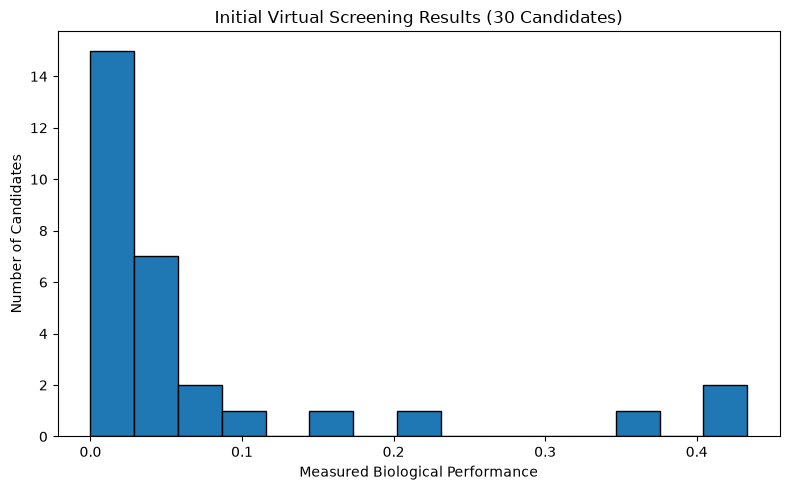

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    initial_screen["measured_performance"],
    bins=15,
    edgecolor="black"
)

ax.set_xlabel("Measured Biological Performance")
ax.set_ylabel("Number of Candidates")
ax.set_title("Initial Virtual Screening Results (30 Candidates)")

plt.tight_layout()
plt.show()


In [5]:
from sklearn.ensemble import RandomForestRegressor

# Molecular properties available to the AI
features = [
    "lipophilicity",
    "molecular_size",
    "charge",
    "flexibility"
]

# Training inputs
X_train = initial_screen[features]

# Experimental results the model learns to predict
y_train = initial_screen["measured_performance"]

# Create the AI model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("AI model trained successfully!")

AI model trained successfully!


In [6]:
# Identify candidates not yet tested
untested = candidates[
    ~candidates["candidate_id"].isin(initial_ids)
].copy()

# Give the AI only the molecular features
X_untested = untested[features]

# Predict performance
untested["predicted_performance"] = model.predict(X_untested)

# Rank candidates by predicted performance
ranked_candidates = untested.sort_values(
    "predicted_performance",
    ascending=False
)

print("Top 10 AI-selected candidates:")

display(
    ranked_candidates[
        [
            "candidate_id",
            "lipophilicity",
            "molecular_size",
            "charge",
            "flexibility",
            "predicted_performance"
        ]
    ].head(10)
)


Top 10 AI-selected candidates:


,candidate_id,lipophilicity,molecular_size,charge,flexibility,predicted_performance
636,636,6.753056,582.348082,-0.142393,0.822127,0.350750
222,222,6.628642,926.158048,-0.335353,0.759926,0.344910
459,459,6.364083,564.816876,0.109599,0.791847,0.343762
585,585,6.308322,957.163748,-0.218973,0.800713,0.337787
711,711,6.745975,567.948214,-1.010974,0.758372,0.333918
478,478,6.346291,640.396429,-0.506466,0.932110,0.332974
12,12,6.438651,630.948781,-1.440850,0.762073,0.327020
447,447,6.115436,676.053219,-0.382894,0.756547,0.324436
597,597,6.337698,422.823573,-0.372577,0.882848,0.317661
492,492,6.524331,753.728611,-1.796224,0.855963,0.310772


In [7]:
# Select the 20 candidates with highest predicted performance
ai_selected = ranked_candidates.head(20).copy()

print("AI-selected candidates:", len(ai_selected))

display(
    ai_selected[
        [
            "candidate_id",
            "predicted_performance"
        ]
    ].head()
)

AI-selected candidates: 20


,candidate_id,predicted_performance
636,636,0.350750
222,222,0.344910
459,459,0.343762
585,585,0.337787
711,711,0.333918


In [8]:
# Simulate experiments for AI-selected candidates
ai_selected["measured_performance"] = (
    ai_selected["true_performance"]
    + rng.normal(0, 0.03, len(ai_selected))
)

# Keep measurements between 0 and 1
ai_selected["measured_performance"] = (
    ai_selected["measured_performance"].clip(0, 1)
)

print(
    "Best AI-selected measured performance:",
    round(ai_selected["measured_performance"].max(), 3)
)

display(
    ai_selected[
        [
            "candidate_id",
            "predicted_performance",
            "measured_performance"
        ]
    ].head(10)
)

Best AI-selected measured performance: 0.73


,candidate_id,predicted_performance,measured_performance
636,636,0.350750,0.577277
222,222,0.344910,0.003995
459,459,0.343762,0.712210
585,585,0.337787,0.032251
711,711,0.333918,0.169780
478,478,0.332974,0.509143
12,12,0.327020,0.046489
447,447,0.324436,0.459382
597,597,0.317661,0.260645
492,492,0.310772,0.006658


In [9]:
# Randomly select 20 untested candidates
random_selected = untested.sample(
    n=20,
    random_state=123
).copy()

# Simulate their experimental measurements
random_selected["measured_performance"] = (
    random_selected["true_performance"]
    + rng.normal(0, 0.03, len(random_selected))
)

random_selected["measured_performance"] = (
    random_selected["measured_performance"].clip(0, 1)
)

print(
    "Best random-screened performance:",
    round(random_selected["measured_performance"].max(), 3)
)

print(
    "Average AI-selected performance:",
    round(ai_selected["measured_performance"].mean(), 3)
)

print(
    "Average random-selected performance:",
    round(random_selected["measured_performance"].mean(), 3)
)


Best random-screened performance: 0.558
Average AI-selected performance: 0.281
Average random-selected performance: 0.076


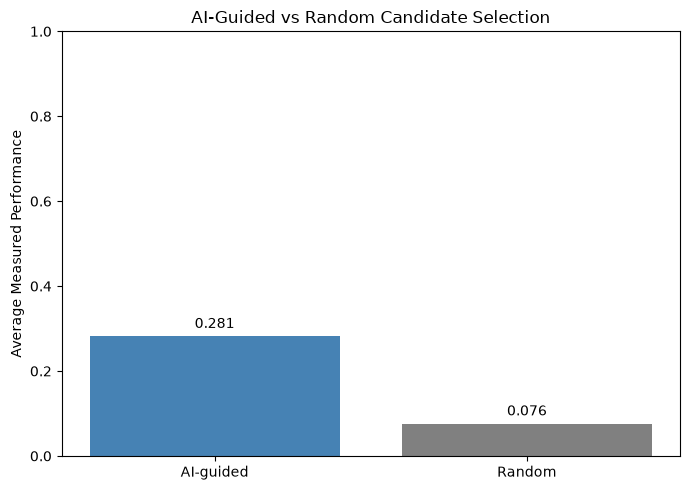

In [10]:
# Calculate average experimental performance
strategies = ["AI-guided", "Random"]

average_performance = [
    ai_selected["measured_performance"].mean(),
    random_selected["measured_performance"].mean()
]

# Create comparison plot
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    strategies,
    average_performance,
    color=["steelblue", "gray"]
)

ax.set_ylabel("Average Measured Performance")
ax.set_title("AI-Guided vs Random Candidate Selection")
ax.set_ylim(0, 1)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [11]:
# Combine initial and AI-guided experimental results
training_data = pd.concat(
    [initial_screen, ai_selected],
    ignore_index=True
)

print("Total experiments:", len(training_data))

# Retrain the model using all 50 measurements
model.fit(
    training_data[features],
    training_data["measured_performance"]
)

print("AI model retrained with new experimental data!")


Total experiments: 50
AI model retrained with new experimental data!


In [12]:
# Simulate experimental measurements
def run_experiment(selected_candidates, rng):
    measured = selected_candidates.copy()

    measured["measured_performance"] = (
        measured["true_performance"]
        + rng.normal(0, 0.03, len(measured))
    ).clip(0, 1)

    # Return only information available to the AI
    return measured[
        ["candidate_id"] + features + ["measured_performance"]
    ].copy()


In [13]:
from sklearn.ensemble import RandomForestRegressor

def discovery_campaign(strategy, seed=123, starting_screen=None):
    experiment_rng = np.random.default_rng(seed)
    if starting_screen is None:
        starting_screen = initial_screen

    # Both strategies start with the same 30 experiments
    training = starting_screen[
        ["candidate_id"] + features + ["measured_performance"]
    ].copy()

    history = []

    for round_number in range(1, 11):

        # Identify untested candidates
        untested_pool = candidates[
            ~candidates["candidate_id"].isin(
                training["candidate_id"]
            )
        ].copy()

        if strategy in ["AI", "UCB"]:

            # Train the AI model
            ai_model = RandomForestRegressor(
                n_estimators=200,
                random_state=42
            )

            ai_model.fit(
                training[features],
                training["measured_performance"]
            )

            # Predict performance and uncertainty
            predictions, uncertainty = predict_with_uncertainty(
                ai_model,
                untested_pool[features]
            )

            untested_pool["prediction"] = predictions
            untested_pool["uncertainty"] = uncertainty

            if strategy == "AI":
                # Select highest predicted performers
                untested_pool["score"] = predictions

            elif strategy == "UCB":
                # Balance performance and uncertainty
                beta = 1.0
                untested_pool["score"] = (
                    predictions + beta * uncertainty
                )

            selected = untested_pool.nlargest(
                20, "score"
            )




        elif strategy == "Random":
            selected = untested_pool.sample(
                n=20,
                random_state=seed + round_number
            )

        else:
            raise ValueError("Unknown strategy")

        # Perform virtual experiments
        results = run_experiment(
            selected,
            experiment_rng
        )

        # Add new measurements to training data
        training = pd.concat(
            [training, results],
            ignore_index=True
        )

        # Record discovery performance
        history.append({
            "round": round_number,
            "total_experiments": len(training),
            "best_performance": training[
                "measured_performance"
            ].max(),
            "round_average": results[
                "measured_performance"
            ].mean()
        })

    return pd.DataFrame(history), training


In [15]:
def predict_with_uncertainty(model, X):

    # Convert pandas DataFrame to NumPy array
    X_array = X.to_numpy()

    # Get predictions from each tree
    tree_predictions = np.array([
        tree.predict(X_array)
        for tree in model.estimators_
    ])

    # Calculate predicted performance
    mean_prediction = tree_predictions.mean(axis=0)

    # Calculate uncertainty
    uncertainty = tree_predictions.std(axis=0)

    return mean_prediction, uncertainty


In [16]:
ai_history, ai_training = discovery_campaign("AI")
ucb_history, ucb_training = discovery_campaign("UCB")
random_history, random_training = discovery_campaign("Random")

print("All three campaigns completed!")


All three campaigns completed!


In [17]:
comparison = pd.DataFrame({
    "Strategy": ["AI", "UCB", "Random"],
    "Best Performance": [
        ai_history["best_performance"].iloc[-1],
        ucb_history["best_performance"].iloc[-1],
        random_history["best_performance"].iloc[-1]
    ],
    "Final Round Average": [
        ai_history["round_average"].iloc[-1],
        ucb_history["round_average"].iloc[-1],
        random_history["round_average"].iloc[-1]
    ]
})

display(comparison.round(3))


,Strategy,Best Performance,Final Round Average
0,AI,0.800,0.115
1,UCB,0.817,0.113
2,Random,0.671,0.146


In [18]:
# Find the best possible candidate in our virtual library
best_possible = candidates["true_performance"].max()

print("Best possible performance:", round(best_possible, 3))
print()

# Compare strategies using true performance
for name, training in [
    ("AI", ai_training),
    ("UCB", ucb_training),
    ("Random", random_training)
]:

    # Identify candidates tested by this strategy
    tested = candidates[
        candidates["candidate_id"].isin(
            training["candidate_id"]
        )
    ]

    # Find the best true performance among tested candidates
    best_true = tested["true_performance"].max()

    # Calculate how close it is to the library optimum
    percent_optimum = 100 * best_true / best_possible

    print(
        f"{name}: Best true performance = {best_true:.3f}, "
        f"Library optimum recovered = {percent_optimum:.1f}%"
    )

Best possible performance: 0.814

AI: Best true performance = 0.814, Library optimum recovered = 100.0%
UCB: Best true performance = 0.814, Library optimum recovered = 100.0%
Random: Best true performance = 0.646, Library optimum recovered = 79.4%


In [19]:
# Repeat the experiment using different random seeds

all_results = []

for seed in range(20):

    # Create a new initial screen
    simulation_rng = np.random.default_rng(seed)

    starting_ids = simulation_rng.choice(
        candidates["candidate_id"],
        size=30,
        replace=False
    )

    starting_candidates = candidates[
        candidates["candidate_id"].isin(starting_ids)
    ].copy()

    # Simulate initial measurements
    starting_screen = run_experiment(
        starting_candidates,
        simulation_rng
    )

    # Run each strategy from the same starting screen
    for strategy in ["AI", "UCB", "Random"]:

        history, training = discovery_campaign(
            strategy=strategy,
            seed=seed,
            starting_screen=starting_screen
        )

        # Find best true performance among tested candidates
        tested = candidates[
            candidates["candidate_id"].isin(
                training["candidate_id"]
            )
        ]

        best_true = tested["true_performance"].max()

        all_results.append({
            "seed": seed,
            "strategy": strategy,
            "best_true_performance": best_true,
            "percent_optimum": (
                100 * best_true /
                candidates["true_performance"].max()
            )
        })

results_df = pd.DataFrame(all_results)

display(results_df.head())


,seed,strategy,best_true_performance,percent_optimum
0,0,AI,0.813621,100.000000
1,0,UCB,0.813621,100.000000
2,0,Random,0.610077,74.982893
3,1,AI,0.813621,100.000000
4,1,UCB,0.813621,100.000000


In [20]:
summary = (
    results_df.groupby("strategy")
    .agg(
        mean_performance=("best_true_performance", "mean"),
        std_performance=("best_true_performance", "std"),
        mean_percent_optimum=("percent_optimum", "mean")
    )
    .round(3)
)

display(summary)

,mean_performance,std_performance,mean_percent_optimum
strategy,,,
AI,0.814,0.000,100.000
Random,0.695,0.082,85.467
UCB,0.814,0.000,100.000


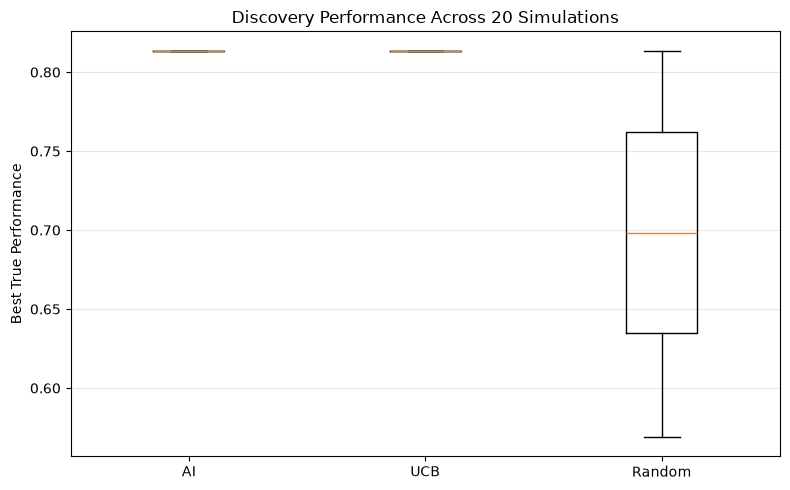

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))

strategies = ["AI", "UCB", "Random"]

data = [
    results_df.loc[
        results_df["strategy"] == strategy,
        "best_true_performance"
    ].values
    for strategy in strategies
]

ax.boxplot(data, tick_labels=strategies)

ax.set_ylabel("Best True Performance")
ax.set_title("Discovery Performance Across 20 Simulations")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:
def experiments_to_target(training, candidates, threshold=0.95):

    # Best possible true performance
    optimum = candidates["true_performance"].max()

    # Attach hidden true performance to tested candidates
    tested = training[["candidate_id"]].merge(
        candidates[["candidate_id", "true_performance"]],
        on="candidate_id",
        how="left"
    )

    # Identify candidates reaching the target
    hits = tested[
        tested["true_performance"] >= threshold * optimum
    ]

    if len(hits) == 0:
        return None

    # Training rows are in experimental order
    return int(hits.index.min() + 1)



for name, training in [
    ("AI", ai_training),
    ("UCB", ucb_training),
    ("Random", random_training)
]:
    n = experiments_to_target(training, candidates)

    print(
        f"{name}:",
        n if n is not None else "Target not reached",
        "experiments"
    )


AI: 94 experiments
UCB: 75 experiments
Random: Target not reached experiments


In [23]:
speed_results = []

for seed in range(20):

    simulation_rng = np.random.default_rng(seed)

    starting_ids = simulation_rng.choice(
        candidates["candidate_id"],
        size=30,
        replace=False
    )

    starting_candidates = candidates[
        candidates["candidate_id"].isin(starting_ids)
    ].copy()

    starting_screen = run_experiment(
        starting_candidates,
        simulation_rng
    )

    for strategy in ["AI", "UCB", "Random"]:

        history, training = discovery_campaign(
            strategy=strategy,
            seed=seed,
            starting_screen=starting_screen
        )

        experiments_needed = experiments_to_target(
            training,
            candidates,
            threshold=0.95
        )

        # Convert experiment count into completed batch budget
        if experiments_needed is None:
            batch_budget = np.nan
        elif experiments_needed <= 30:
            batch_budget = 30
        else:
            batch_budget = (
                30 + 20 * np.ceil(
                    (experiments_needed - 30) / 20
                )
            )

        speed_results.append({
            "seed": seed,
            "strategy": strategy,
            "experiments_to_target": experiments_needed,
            "batch_budget": batch_budget
        })

speed_df = pd.DataFrame(speed_results)

display(speed_df.head())


,seed,strategy,experiments_to_target,batch_budget
0,0,AI,36.0,50.0
1,0,UCB,43.0,50.0
2,0,Random,NaN,NaN
3,1,AI,91.0,110.0
4,1,UCB,76.0,90.0


In [24]:
speed_summary = (
    speed_df.groupby("strategy")
    .agg(
        success_rate=(
            "batch_budget",
            lambda x: x.notna().mean() * 100
        ),
        mean_batch_budget=(
            "batch_budget",
            "mean"
        ),
        median_batch_budget=(
            "batch_budget",
            "median"
        )
    )
    .round(1)
)

display(speed_summary)


,success_rate,mean_batch_budget,median_batch_budget
strategy,,,
AI,100.0,71.0,70.0
Random,10.0,130.0,130.0
UCB,100.0,75.0,70.0


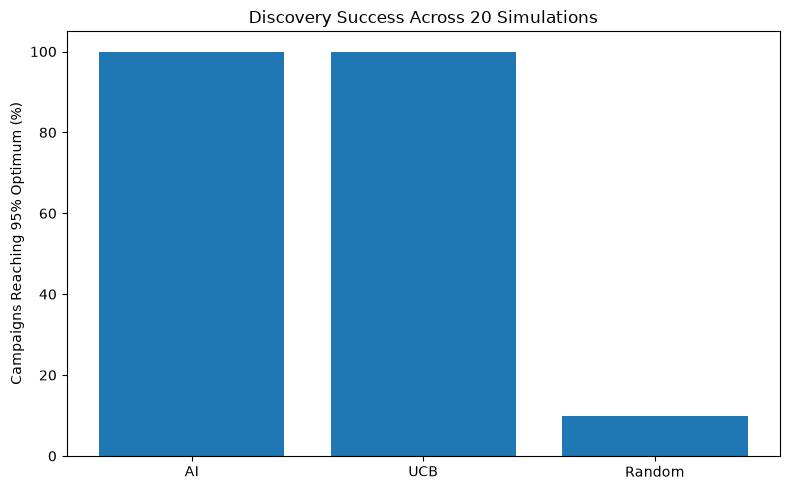

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

strategies = ["AI", "UCB", "Random"]

success_rates = [
    speed_summary.loc[s, "success_rate"]
    for s in strategies
]

ax.bar(strategies, success_rates)

ax.set_ylabel("Campaigns Reaching 95% Optimum (%)")
ax.set_ylim(0, 105)
ax.set_title("Discovery Success Across 20 Simulations")

plt.tight_layout()
plt.show()
